In [13]:
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from collections import Counter
from torch.utils.data import random_split, DataLoader
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import time

# Task 1. Study and Prepare the Data

In [14]:
# Download and load CIFAR-10
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True,transform=transforms.ToTensor())

test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True,transform=transforms.ToTensor())

In [15]:
# Analyze the dataset
classes = train_dataset.classes

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Image dimensions:", train_dataset.data.shape[1:])
print("Number of classes:", len(classes))
print("Classes:", classes)

Training samples: 50000
Test samples: 10000
Image dimensions: (32, 32, 3)
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [16]:
# Inspect class distribution
class_counts = Counter(train_dataset.targets)

for i, class_name in enumerate(classes):
    print(f"{class_name}: {class_counts[i]}")

airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000


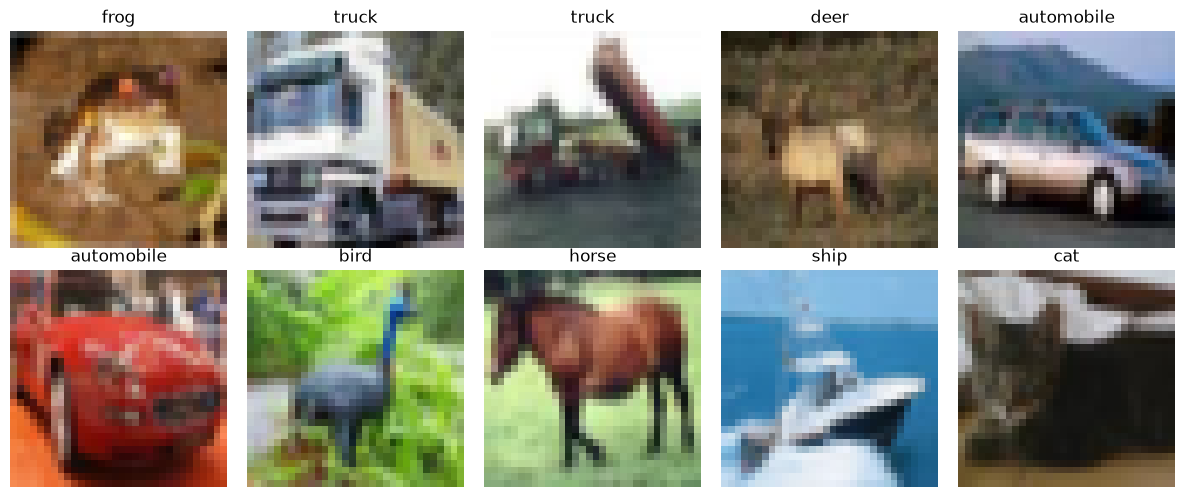

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = train_dataset.data[i]
    label = train_dataset.targets[i]

    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
# Normalization
# Source: https://stackoverflow.com/questions/66678052/how-to-calculate-the-mean-and-the-std-of-cifar10-data
mean = [0.49139968, 0.48215827 ,0.44653124]
std =  [0.24703233, 0.24348505, 0.26158768]
train_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

In [19]:
# Create all 3 splits
seed = 587
rng = np.random.default_rng(seed)

train_subset, val_subset = random_split(
    train_dataset, [40000, 10000],
    generator=torch.Generator().manual_seed(seed)
)
 # Test already defined in the first cell

print("Training:", len(train_subset))
print("Validation:", len(val_subset))
print("Test:", len(test_dataset))

Training: 40000
Validation: 10000
Test: 10000


In [20]:
# Data loaders for efficient batch processing
train_loader = DataLoader(train_subset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# Task 2. Implement and Compare the Models


In [21]:
if torch.cuda.is_available(): device = torch.device("cuda")
elif torch.backends.mps.is_available(): device = torch.device("mps")
else: device = torch.device("cpu")

In [22]:
# AlexNet
#width and depth can be changed more easily with this new implementation. extra_convs is depth
class AlexNet(nn.Module):
    
    def __init__(self, num_classes=10, width=1.0, extra_convs=0, dropout=0):
        super().__init__()
        c1, c2, c3, c4, c5 = [int(c * width) for c in (64, 192, 384, 256, 256)]
        h1, h2 = int(1024 * width), int(512 * width)
        layers = [
            nn.Conv2d(3, c1, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(c1, c2, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(c2, c3, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(c3, c4, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(c4, c5, 3, padding=1), nn.ReLU(inplace=True),
        ]
        for _ in range(extra_convs):
            layers += [nn.Conv2d(c5, c5, 3, padding=1), nn.ReLU(inplace=True)]
        layers.append(nn.MaxPool2d(2, 2))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c5 * 4 * 4, h1), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(h1, h2), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(h2, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [23]:
# ResNet
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out += identity
        out = self.relu(out)

        return out

##width and depth can be changed more easily with this new implementation. Blocks is depth
class ResNet18(nn.Module):
    def __init__(self, num_classes=10, width=64, blocks=(2, 2, 2, 2), dropout=0.0):
        super().__init__()
        self.in_channels = width
        self.conv1 = nn.Conv2d(3, width, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(width)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self.make_layer(width, blocks[0], stride=1)
        self.layer2 = self.make_layer(width * 2, blocks[1], stride=2)
        self.layer3 = self.make_layer(width * 4, blocks[2], stride=2)
        self.layer4 = self.make_layer(width * 8, blocks[3], stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(width * 8, num_classes)

    def make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock(self.in_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = torch.flatten(self.avgpool(x), 1)
        return self.fc(self.drop(x))

In [24]:
# Initiate models
alexnet = AlexNet().to(device)
resnet = ResNet18().to(device)

In [39]:
# Training configuration
criterion = nn.CrossEntropyLoss()

learning_rate = 0.001
epochs = 10

alexnet_optimizer = torch.optim.Adam(alexnet.parameters(), lr=learning_rate)
resnet_optimizer = torch.optim.Adam(resnet.parameters(), lr=learning_rate)

In [40]:
# Logic to train for a single epoch

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total

    # Evaluate the model
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / len(loader), correct / total

"""
# old one
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)
    """




'\n# old one\ndef train_one_epoch(model, loader, optimizer):\n    model.train()\n    total_loss = 0\n    for images, labels in loader:\n        images, labels = images.to(device), labels.to(device)\n        optimizer.zero_grad()\n        outputs = model(images)\n        loss = criterion(outputs, labels)\n        loss.backward()\n        optimizer.step()\n        total_loss += loss.item()\n    return total_loss / len(loader)\n    '

In [41]:
# Training Loop
def train_model(model, optimizer, name):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_accuracy = 0
    start = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_accuracy = evaluate(model, val_loader)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_accuracy)
        print(
            f"{name} | Epoch {epoch+1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f} | "
            f"Val loss: {val_loss:.4f} | Val accuracy: {val_accuracy:.4f}"
        )
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), f"{name}_best.pth")
            
    history['time'] = time.time() - start
    history['params'] = sum(p.numel() for p in model.parameters())
    print(f"{name} best val acc: {best_accuracy:.4f} | time: {history['time']:.0f}s | params: {history['params']:,}")
    return history

In [42]:
# Run Training
results = {}
results['alex_base'] = train_model(alexnet, alexnet_optimizer, "alexnet")
results['resnet_base'] = train_model(resnet, resnet_optimizer, "resnet")

alexnet | Epoch 1/10 | Train loss: 0.4272 | Train acc: 0.8485 | Val loss: 0.8721 | Val accuracy: 0.7253
alexnet | Epoch 2/10 | Train loss: 0.3451 | Train acc: 0.8777 | Val loss: 0.8906 | Val accuracy: 0.7355
alexnet | Epoch 3/10 | Train loss: 0.2811 | Train acc: 0.9021 | Val loss: 1.0010 | Val accuracy: 0.7328
alexnet | Epoch 4/10 | Train loss: 0.2248 | Train acc: 0.9208 | Val loss: 1.0489 | Val accuracy: 0.7304
alexnet | Epoch 5/10 | Train loss: 0.1852 | Train acc: 0.9349 | Val loss: 1.1381 | Val accuracy: 0.7270
alexnet | Epoch 6/10 | Train loss: 0.1621 | Train acc: 0.9436 | Val loss: 1.1412 | Val accuracy: 0.7307
alexnet | Epoch 7/10 | Train loss: 0.1251 | Train acc: 0.9556 | Val loss: 1.3558 | Val accuracy: 0.7288
alexnet | Epoch 8/10 | Train loss: 0.1205 | Train acc: 0.9596 | Val loss: 1.4008 | Val accuracy: 0.7201
alexnet | Epoch 9/10 | Train loss: 0.1033 | Train acc: 0.9659 | Val loss: 1.4621 | Val accuracy: 0.7202
alexnet | Epoch 10/10 | Train loss: 0.0857 | Train acc: 0.9714 |

In [43]:
# Test both models on their best validation checkpoints
for model, name in [(alexnet, "alexnet"), (resnet, "resnet")]:
    model.load_state_dict(torch.load(f"{name}_best.pth", map_location=device))

    test_loss, test_accuracy = evaluate(model, test_loader)

    print(
        f"{name}: Test loss = {test_loss:.4f}, "
        f"Test accuracy = {test_accuracy:.4f}"
    )

alexnet: Test loss = 0.9171, Test accuracy = 0.7318
resnet: Test loss = 0.8792, Test accuracy = 0.8221


In [44]:
#Helper Functions for plotting
def plot_metrics(history, title="Training Curves"):
    epochs_range = range(1, len(history['train_loss']) + 1)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    
    # Loss plot
    ax1.plot(epochs_range, history['train_loss'], label='Train Loss', color='blue')
    ax1.plot(epochs_range, history['val_loss'], label='Val Loss', color='red', linestyle='--')
    ax1.set_title(f"{title} - Loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)
    
    # Accuracy plot
    ax2.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='blue')
    ax2.plot(epochs_range, history['val_acc'], label='Val Accuracy', color='red', linestyle='--')
    ax2.set_title(f"{title} - Accuracy")
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()



# Overlay plots of same metric
def plot_compare(histories, key='val_acc'):
    for name, h in histories.items():
        plt.plot(range(1, len(h[key]) + 1), h[key], label=name)
    plt.xlabel("Epochs"); plt.ylabel(key); plt.legend(); plt.grid(True); plt.show()

def pick(*names): return {n: results[n] for n in names}

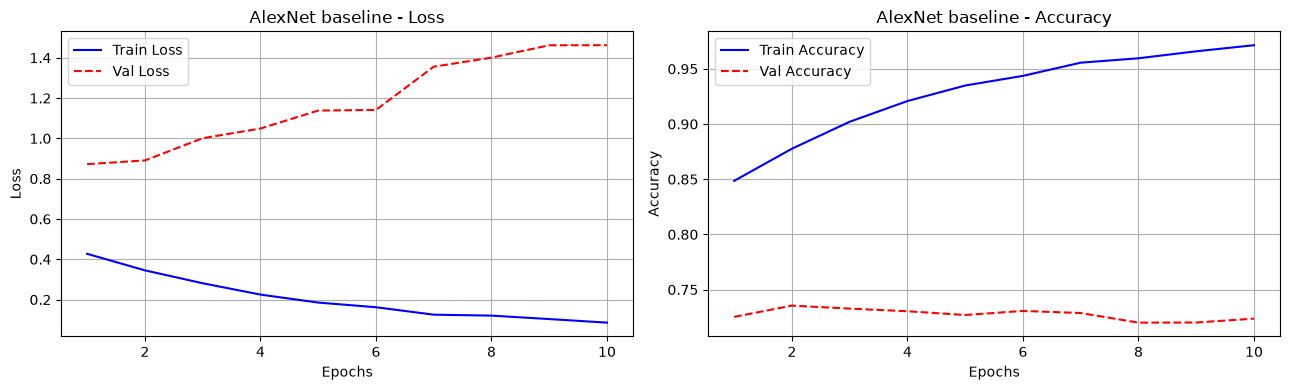

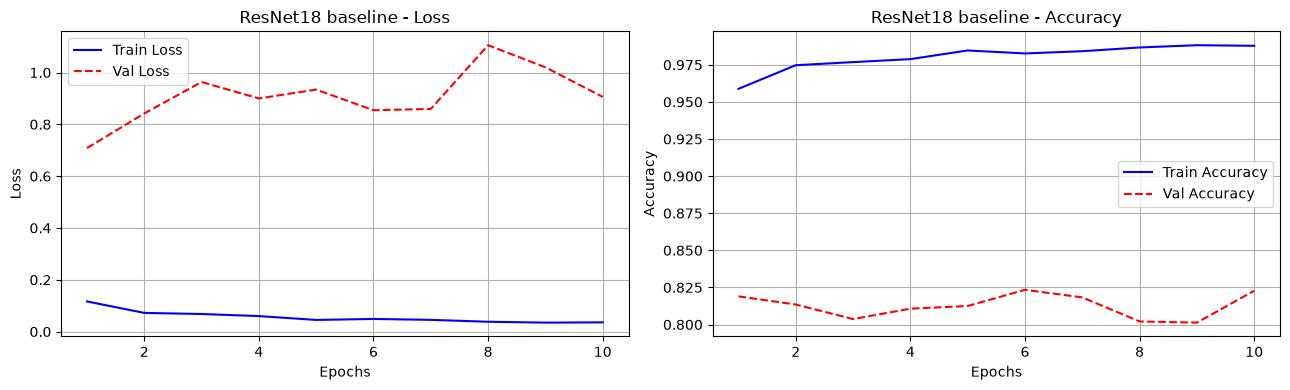

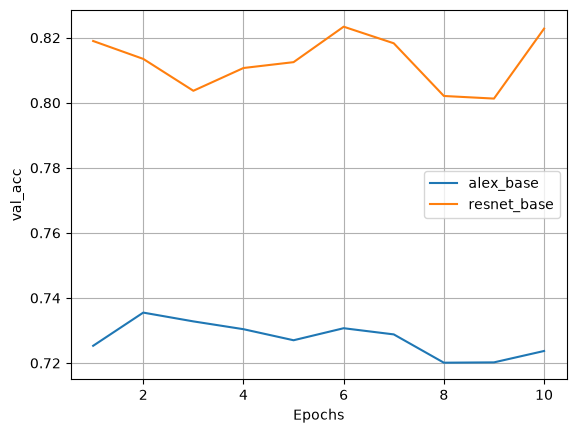

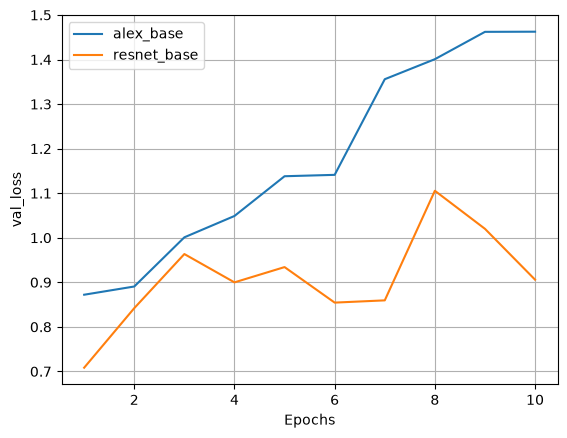

In [45]:
plot_metrics(results['alex_base'], "AlexNet baseline")
plot_metrics(results['resnet_base'], "ResNet18 baseline")

plot_compare(pick('alex_base', 'resnet_base'), 'val_acc')
plot_compare(pick('alex_base', 'resnet_base'), 'val_loss')

# Task 3 Investigate Capacity and Regularization

In [46]:
#resets the state for each run
def run(model, name, weight_decay=0.0):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    return train_model(model, opt, name)

resnet_w32 | Epoch 1/10 | Train loss: 1.3211 | Train acc: 0.5178 | Val loss: 1.8960 | Val accuracy: 0.3997
resnet_w32 | Epoch 2/10 | Train loss: 0.8548 | Train acc: 0.6965 | Val loss: 1.1889 | Val accuracy: 0.6156
resnet_w32 | Epoch 3/10 | Train loss: 0.6502 | Train acc: 0.7709 | Val loss: 0.8194 | Val accuracy: 0.7275
resnet_w32 | Epoch 4/10 | Train loss: 0.5193 | Train acc: 0.8179 | Val loss: 0.6873 | Val accuracy: 0.7676
resnet_w32 | Epoch 5/10 | Train loss: 0.4107 | Train acc: 0.8554 | Val loss: 0.6699 | Val accuracy: 0.7763
resnet_w32 | Epoch 6/10 | Train loss: 0.3183 | Train acc: 0.8876 | Val loss: 0.6664 | Val accuracy: 0.7787
resnet_w32 | Epoch 7/10 | Train loss: 0.2363 | Train acc: 0.9173 | Val loss: 0.6999 | Val accuracy: 0.7846
resnet_w32 | Epoch 8/10 | Train loss: 0.1877 | Train acc: 0.9350 | Val loss: 0.6651 | Val accuracy: 0.8003
resnet_w32 | Epoch 9/10 | Train loss: 0.1390 | Train acc: 0.9513 | Val loss: 0.7761 | Val accuracy: 0.7880
resnet_w32 | Epoch 10/10 | Train loss

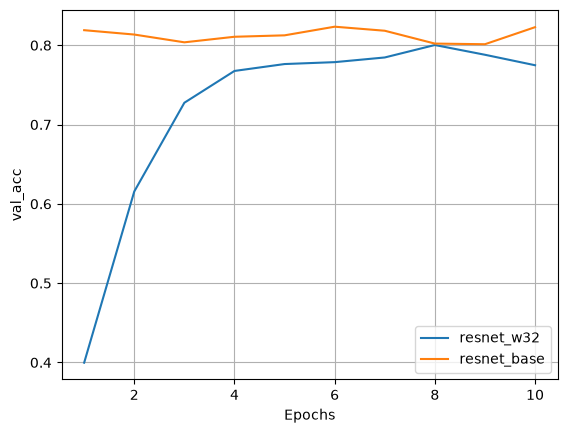

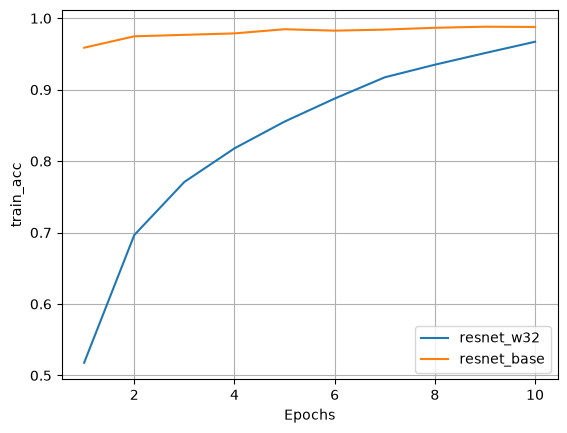

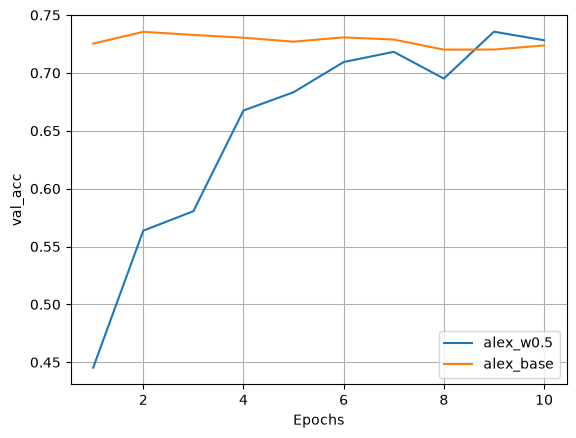

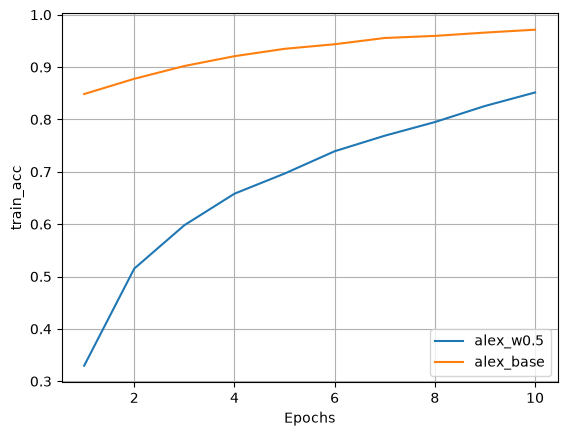

In [47]:
# Width
#normal width for both is (64,128,256,...)

#Alex with half the width (instead of 64,128... , it is 32, 64,...)
results['alex_w0.5'] = run(AlexNet(width=0.5), "alex_w0.5")


#Same deal with Resnet
results['resnet_w32'] = run(ResNet18(width=32), "resnet_w32")



plot_compare(pick('alex_w0.5', 'alex_base'), 'train_acc')
plot_compare(pick('alex_w0.5', 'alex_base'), 'val_acc')

plot_compare(pick('resnet_w32', 'resnet_base'), 'train_acc')
plot_compare(pick('resnet_w32', 'resnet_base'), 'val_acc')


#Both narrow implementations reach a bit lower acc for both train, but they reach it with less time and much less parameters.
#narrower alex reaches a bit better val acc and has less overfitting which is an improvement

#Overfitting still appears but a but less as the trains and val acc are closer

alex_extra1 | Epoch 1/10 | Train loss: 1.8092 | Train acc: 0.3157 | Val loss: 1.5046 | Val accuracy: 0.4287
alex_extra1 | Epoch 2/10 | Train loss: 1.3707 | Train acc: 0.4893 | Val loss: 1.1943 | Val accuracy: 0.5629
alex_extra1 | Epoch 3/10 | Train loss: 1.1151 | Train acc: 0.5969 | Val loss: 1.0909 | Val accuracy: 0.6125
alex_extra1 | Epoch 4/10 | Train loss: 0.9669 | Train acc: 0.6525 | Val loss: 0.9797 | Val accuracy: 0.6528
alex_extra1 | Epoch 5/10 | Train loss: 0.8397 | Train acc: 0.7013 | Val loss: 0.8826 | Val accuracy: 0.6893
alex_extra1 | Epoch 6/10 | Train loss: 0.7344 | Train acc: 0.7389 | Val loss: 0.8700 | Val accuracy: 0.7031
alex_extra1 | Epoch 7/10 | Train loss: 0.6316 | Train acc: 0.7764 | Val loss: 0.8302 | Val accuracy: 0.7312
alex_extra1 | Epoch 8/10 | Train loss: 0.5455 | Train acc: 0.8068 | Val loss: 0.7705 | Val accuracy: 0.7446
alex_extra1 | Epoch 9/10 | Train loss: 0.4591 | Train acc: 0.8382 | Val loss: 0.8195 | Val accuracy: 0.7306
alex_extra1 | Epoch 10/10 | 

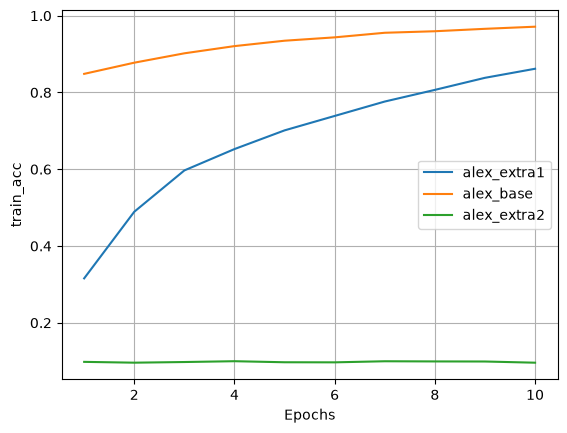

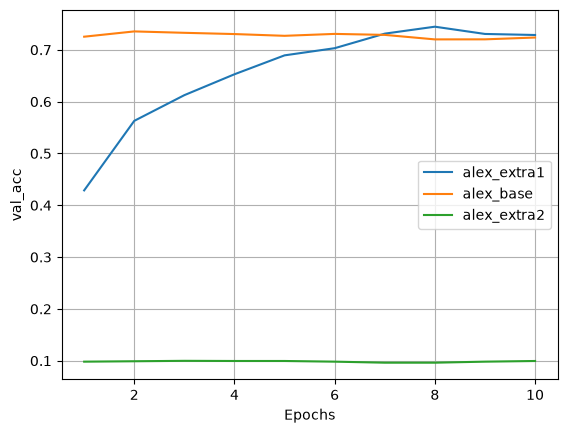

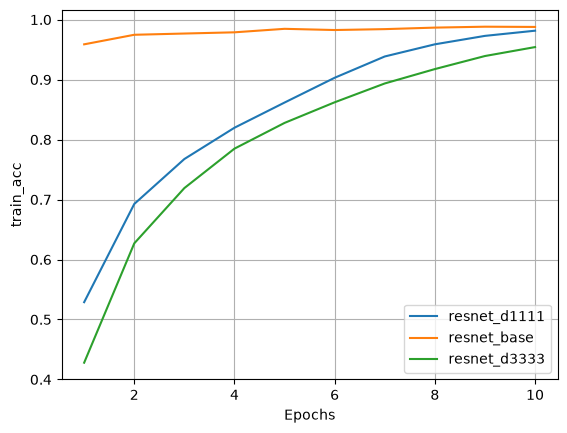

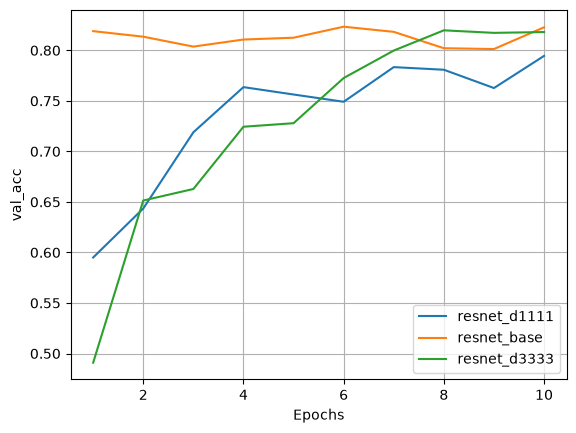

In [48]:
# Depth


#Original depth is 5 conv layers. Each extra conv layer makes the model deeper
results['alex_extra1']  = run(AlexNet(extra_convs=1), "alex_extra1")
results['alex_extra2']  = run(AlexNet(extra_convs=2), "alex_extra2")

# Original Depth is [2,2,2,2]. setting it to 1,1,1,1 makes it more shallow, and 3,3,3,3 makes it deeper
results['resnet_d1111'] = run(ResNet18(blocks=(1,1,1,1)), "resnet_d1111")
results['resnet_d3333'] = run(ResNet18(blocks=(3,3,3,3)), "resnet_d3333")


plot_compare(pick('alex_extra1', 'alex_base', 'alex_extra2'), 'train_acc')
plot_compare(pick('alex_extra1', 'alex_base', 'alex_extra2'), 'val_acc')

plot_compare(pick('resnet_d1111', 'resnet_base', 'resnet_d3333'), 'train_acc')
plot_compare(pick('resnet_d1111', 'resnet_base', 'resnet_d3333'), 'val_acc')


#For alexnet, it reaches lower training accuracy but it takes longer with more paramters. 
#But the overfitting is less since the train acc is closer to val acc
#They reach almost the same val acc, which makes it not worth the trouble
#When adding 2 extra conv layer, we get the "vanishing gradient" problem where the acc cannot get over 9%
#Making the model much deeper without any other optimization techniques causes this

#for resnet the deeper it goes the less training acc it has, which in theory also is bad since it takes more effort and gets less results.
#it is worthy to note that the overfitting is the smallest with the 2 extra conv model, but it still has lower val acc

alex_drop20 | Epoch 1/10 | Train loss: 1.8928 | Train acc: 0.2786 | Val loss: 1.5839 | Val accuracy: 0.3990
alex_drop20 | Epoch 2/10 | Train loss: 1.4325 | Train acc: 0.4657 | Val loss: 1.3059 | Val accuracy: 0.5195
alex_drop20 | Epoch 3/10 | Train loss: 1.2187 | Train acc: 0.5548 | Val loss: 1.1376 | Val accuracy: 0.5910
alex_drop20 | Epoch 4/10 | Train loss: 1.0735 | Train acc: 0.6143 | Val loss: 1.0696 | Val accuracy: 0.6172
alex_drop20 | Epoch 5/10 | Train loss: 0.9685 | Train acc: 0.6555 | Val loss: 0.9621 | Val accuracy: 0.6604
alex_drop20 | Epoch 6/10 | Train loss: 0.8854 | Train acc: 0.6872 | Val loss: 0.9460 | Val accuracy: 0.6736
alex_drop20 | Epoch 7/10 | Train loss: 0.8020 | Train acc: 0.7150 | Val loss: 0.9139 | Val accuracy: 0.6824
alex_drop20 | Epoch 8/10 | Train loss: 0.7305 | Train acc: 0.7430 | Val loss: 0.8623 | Val accuracy: 0.7030
alex_drop20 | Epoch 9/10 | Train loss: 0.6715 | Train acc: 0.7638 | Val loss: 0.8322 | Val accuracy: 0.7162
alex_drop20 | Epoch 10/10 | 

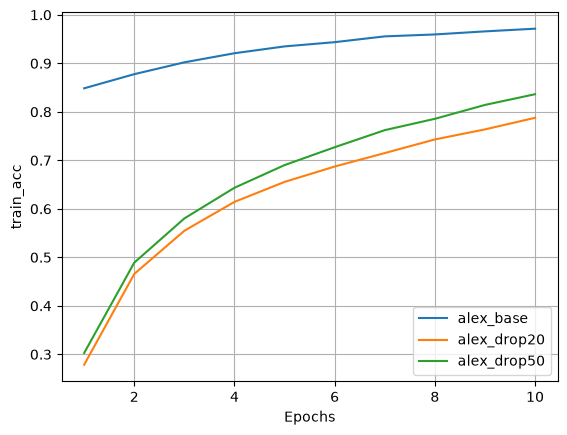

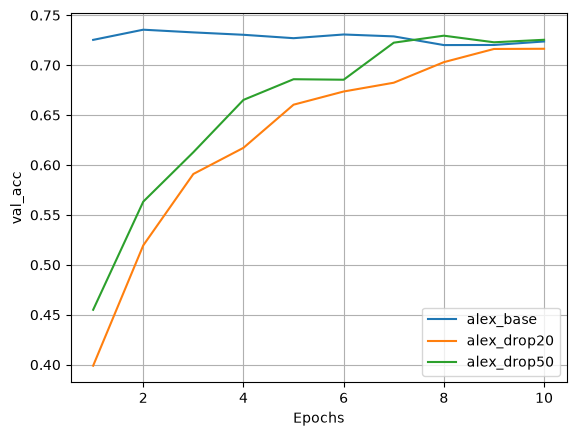

In [49]:
# Dropout 
#ResNet have built in batchNorm so it wouldn't make much sense to do dropout optimization too.
#number is percentage of nodes dropped. 0 is baseline, 0.2 is 20% (moderate), and 50% is high

results['alex_drop20'] = run(AlexNet(dropout=0.2), "alex_drop20")
results['alex_drop50']   = run(AlexNet(dropout=0.5), "alex_drop50")

plot_compare(pick('alex_drop20', 'alex_base', 'alex_drop50'), 'train_acc')
plot_compare(pick('alex_drop20','alex_base', 'alex_drop50'), 'val_acc')



#The best opt for now. Although they reach less training acc, they reach similar val acc, and the 50 version even has a tiny bit more val acc
#They both have less overfitting
#it takes a few sec more which isn't an issue.

alex_l2 | Epoch 1/10 | Train loss: 1.8431 | Train acc: 0.2981 | Val loss: 1.5412 | Val accuracy: 0.4221
alex_l2 | Epoch 2/10 | Train loss: 1.4085 | Train acc: 0.4785 | Val loss: 1.2552 | Val accuracy: 0.5429
alex_l2 | Epoch 3/10 | Train loss: 1.1960 | Train acc: 0.5616 | Val loss: 1.2173 | Val accuracy: 0.5635
alex_l2 | Epoch 4/10 | Train loss: 1.0614 | Train acc: 0.6161 | Val loss: 1.0568 | Val accuracy: 0.6261
alex_l2 | Epoch 5/10 | Train loss: 0.9681 | Train acc: 0.6519 | Val loss: 0.9788 | Val accuracy: 0.6552
alex_l2 | Epoch 6/10 | Train loss: 0.8542 | Train acc: 0.6960 | Val loss: 0.8943 | Val accuracy: 0.6883
alex_l2 | Epoch 7/10 | Train loss: 0.7655 | Train acc: 0.7288 | Val loss: 0.8834 | Val accuracy: 0.6928
alex_l2 | Epoch 8/10 | Train loss: 0.6841 | Train acc: 0.7555 | Val loss: 0.8345 | Val accuracy: 0.7124
alex_l2 | Epoch 9/10 | Train loss: 0.6114 | Train acc: 0.7844 | Val loss: 0.7795 | Val accuracy: 0.7319
alex_l2 | Epoch 10/10 | Train loss: 0.5401 | Train acc: 0.8091 |

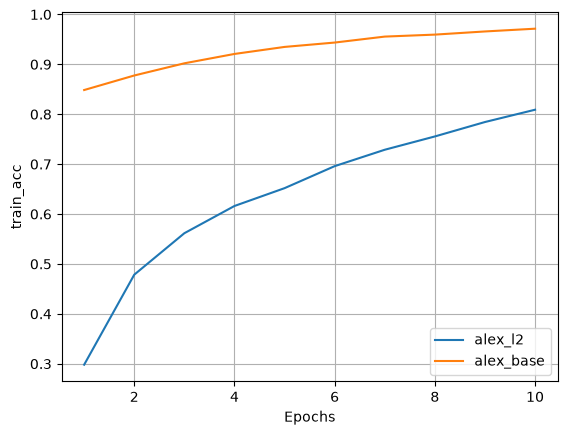

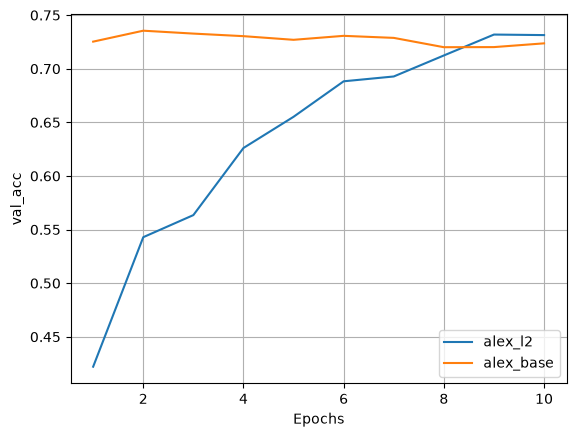

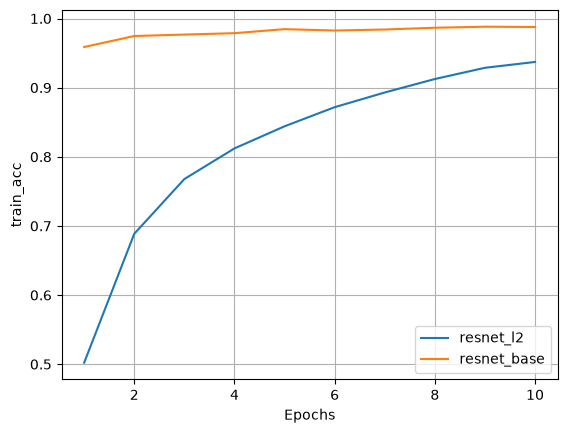

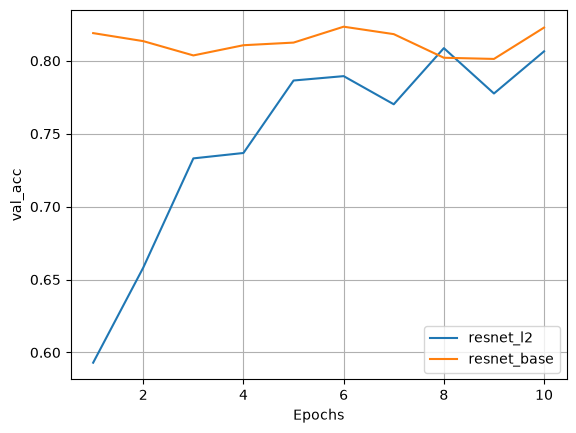

In [50]:
# L2 Regularization(Implemented with weight decay)
#A moderate value of 1e-4 was chosen. This might help with overfitting
#combination of batchNorm in Resnet and this might be interesting to comment on

results['alex_l2']   = run(AlexNet(), "alex_l2", weight_decay=1e-4)
results['resnet_l2'] = run(ResNet18(), "resnet_l2", weight_decay=1e-4)



plot_compare(pick('alex_l2', 'alex_base'), 'train_acc')
plot_compare(pick('alex_l2', 'alex_base'), 'val_acc')

plot_compare(pick('resnet_l2', 'resnet_base'), 'train_acc')
plot_compare(pick('resnet_l2', 'resnet_base'), 'val_acc')


#For alex it reaches less train acc but higher val acc, which means less overfitting with the same nb of paramters and same time
#for resnet it has less train and val acc, but still less overfitting